# Kertenkele Verisiyle Karar Ağacı Oluşturma
**Bilgisayar Destekli Matematik Öğretimi — Final Ödevi**

Ad-Soyad: Nadia

Bu not defterinde aynı kertenkele veri setiyle **üç farklı soru** soruyorum ve her biri için ayrı bir karar ağacı kuruyorum:

1. **Ağaç 1 — Yaşam Alanı:** Bir kertenkelenin ölçülerine bakarak *nerede yaşadığını* (Yer / Kaya / Ağaç) tahmin edebilir miyim?
2. **Ağaç 2 — Tür:** Ölçülere bakarak *hangi türden* (Anolis / Sceloporus / Uta) olduğunu tahmin edebilir miyim?
3. **Ağaç 3 — Cinsiyet:** Ölçülere bakarak *cinsiyetini* (Dişi / Erkek) tahmin edebilir miyim?

Her ağaç aynı 6 adımdan geçiyor; tek değişen hedef değişken (`y`).


## Kütüphaneleri Yükleme
Bu hücreyi bir kez çalıştırman yeterli.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Kütüphaneler başarıyla yüklendi.")

Kütüphaneler başarıyla yüklendi.


# ADIM 1: Veriyi Tanıma
> *Veri kümesiyle tanışmadan model kurmak, soruyu okumadan sınava girmek gibidir.*

**Not:** Dosya adı `lizard_data.csv` (alt çizgi ile). Colab'da dosyayı sol taraftaki 📁 panele sürükledikten sonra çalıştır.

In [ ]:
df = pd.read_csv("lizard_data.csv")
df.head()   # İlk 5 satır

,Tur,Cinsiyet,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,YasamAlani
0,Uta,Disi,43.8,102.2,5.18,21.6,Yer
1,Sceloporus,Disi,62.1,149.8,16.78,29.7,Kaya
2,Uta,Disi,37.6,76.4,4.94,18.5,Yer
3,Sceloporus,Erkek,70.4,170.4,18.23,28.4,Yer
4,Anolis,Disi,52.7,137.9,8.60,25.8,Agac


In [ ]:
print('Satır sayısı:', df.shape[0])
print('Sütun sayısı:', df.shape[1])
print('Sütunlar:', df.columns.tolist())

Satır sayısı: 320
Sütun sayısı: 7
Sütunlar: ['Tur', 'Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']


In [ ]:
# Her yaşam alanından kaç birey var?
df['YasamAlani'].value_counts()

YasamAlani
Yer     151
Kaya     96
Agac     73
Name: count, dtype: int64

In [ ]:
# Sayısal sütunların özeti
df.describe().round(1)

,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu
count,320.0,320.0,320.0,320.0
mean,60.8,145.1,12.5,27.3
std,10.5,26.1,5.7,5.7
min,36.4,76.4,2.6,13.8
25%,52.7,124.4,8.2,22.8
50%,59.8,141.8,10.5,27.2
75%,69.6,166.2,17.4,31.0
max,83.3,209.4,25.9,43.9


In [ ]:
# Tür bazında ortalama ağırlık (alttaki soru için)
df.groupby('Tur')['Kutle'].mean().round(2)

Tur
Anolis         9.88
Sceloporus    19.36
Uta            7.39
Name: Kutle, dtype: float64

### Adım 1 — Soruların Yanıtları

**• Veri kümesinde kaç kertenkele var?**
Toplam **320** kertenkele var (320 satır, 7 sütun).

**• Hangi yaşam alanı en kalabalık, hangisi en az?**
En kalabalık alan **Yer (151 birey)**, ardından **Kaya (96)**, en az ise **Ağaç (73)**. Yani sınıflar dengeli değil; "Yer" sınıfı "Ağaç" sınıfının iki katından fazla.

**• Bu dengesizlik modeli nasıl etkiler?**
Model, gördüğü en kalabalık sınıfa (Yer) doğru bir eğilim (bias) geliştirebilir. Hiçbir şey öğrenmese bile her bireye "Yer" dese %47 doğru çıkar. Bu yüzden modelin başarısını değerlendirirken bu temel orana (baseline) göre bakmak gerekir; %47'nin altına inen bir hata "iş yapıyor" demektir. `train_test_split`'te `stratify=y` kullanmamızın sebebi de bu: bölme sırasında her sınıfın oranını korumak.

**• Kertenkelelerin ortalama ağırlığı nedir? Üç tür için farklı mı?**
Genel ortalama ağırlık **12.5 g**. Ancak tür bazında ciddi fark var: **Sceloporus ≈ 19.4 g**, **Anolis ≈ 9.9 g**, **Uta ≈ 7.4 g**. Sceloporus diğerlerinin yaklaşık iki katı. Bunun nedeni türlerin farklı gövde yapılarına sahip olması; Sceloporus daha iri ve kütleli bir tür. Bu fark, "Tür" tahmini yapan ağacın neden kütleyi ve gövde uzunluğunu kolayca kullanabildiğini açıklıyor.


# ADIM 2: Veriyi Modelin Anlayacağı Hale Getirme
> Karar ağacı yalnızca sayılarla çalışır. `Tur`, `Cinsiyet`, `YasamAlani` gibi metin sütunlarını `pd.get_dummies()` ile 0/1 sütunlarına çeviriyoruz.

Önemli kural: Bir sütunu **hedef (y)** olarak seçtiğimizde, onu **özellikler (X)** içine koymayız — yoksa model cevabı doğrudan görür ve kopya çekmiş olur.

Aşağıda her ağaç için X ve y'yi ayrı ayrı tanımlayacağım. Örnek olarak ilk ağacın (Yaşam Alanı) ayrımını burada gösteriyorum:

In [ ]:
# ÖRNEK: Yaşam Alanı hedefi için X / y ayrımı
ozellikler = ['Tur', 'Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu']
X = pd.get_dummies(df[ozellikler])   # metin sütunları 0/1'e dönüşür
y = df['YasamAlani']

print("X sütunları (get_dummies sonrası):")
print(X.columns.tolist())
print()
print("y (hedef) ilk 5 değer:", y.head().tolist())

X sütunları (get_dummies sonrası):
['GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'Tur_Anolis', 'Tur_Sceloporus', 'Tur_Uta', 'Cinsiyet_Disi', 'Cinsiyet_Erkek']

y (hedef) ilk 5 değer: ['Yer', 'Kaya', 'Yer', 'Yer', 'Agac']


### Adım 2 — Soruların Yanıtları

**Neden `get_dummies` kullandık?**
Karar ağacı "Anolis > Uta" gibi bir karşılaştırma yapamaz çünkü bunlar sayı değil, isim. `get_dummies()` her kategoriyi ayrı bir 0/1 sütununa çeviriyor: `Tur` sütunu → `Tur_Anolis`, `Tur_Sceloporus`, `Tur_Uta`. Böylece model "Tur_Sceloporus == 1 mi?" gibi evet/hayır sorusu sorabiliyor. Buna **one-hot encoding** deniyor.

**Neden hedef değişkeni X'e koymuyoruz?**
Hedefi özelliklere koyarsak model tahmin etmek yerine doğrudan cevabı okur. Bu, sınavda soruyla birlikte cevap anahtarını da vermeye benzer; başarı sahte olur.


# ADIM 3: Eğitim / Test Ayrımı
> Modeli, daha önce görmediği sorularla sınamak istiyoruz. Bu yüzden veriyi %80 eğitim / %20 test olarak ayırıyoruz.

Aşağıdaki kod yukarıda tanımladığımız X ve y (Yaşam Alanı) üzerinde çalışıyor.

In [ ]:
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,       # %20 test
    random_state=42,     # tekrarlanabilirlik için sabit sayı
    stratify=y           # her sınıftan orantılı böl
)

print('Eğitim seti:', len(X_egitim), 'kertenkele')
print('Test seti:  ', len(X_test), 'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())

Eğitim seti: 256 kertenkele
Test seti:   64 kertenkele

Eğitim seti sınıf dağılımı:
YasamAlani
Yer     121
Kaya     77
Agac     58
Name: count, dtype: int64


### Adım 3 — Soruların Yanıtları

**• `stratify=y` parametresini kaldırırsanız ne değişir?**
`stratify` olmadan bölme tamamen rastgele yapılır. O zaman şanssızlık sonucu test setinde "Ağaç" sınıfından çok az birey kalabilir (zaten en az olan sınıf), hatta bazı sınıflar eğitimde eksik temsil edilebilir. Bu da hata oranını yanıltıcı şekilde yüksek ya da düşük gösterir. `stratify=y` her sınıfın %20'sini teste koyarak dağılımı korur, ölçümü güvenilir kılar. Aşağıdaki hücrede deneyip farkı görebilirsin.

**• `random_state=42` yerine `random_state=7` yazarsanız sonuç değişir mi?**
Evet, değişir. `random_state` hangi bireylerin eğitime hangilerinin teste düşeceğini belirleyen rastgeleliğin tohumu. Farklı tohum → farklı bölünme → biraz farklı hata oranları. Ama büyük resim (hangi derinlikten sonra overfitting başladığı gibi) genelde benzer kalır. Sabit tutmamızın tek sebebi: herkes aynı sonucu görsün, tekrarlanabilir olsun.


In [ ]:
# DENEME: stratify olmadan bölme — test setinde sınıf dağılımı bozulur mu?
_, _, _, y_test_strafiz = train_test_split(X, y, test_size=0.2, random_state=42)  # stratify YOK
print("stratify YOKKEN test seti dağılımı:")
print(y_test_strafiz.value_counts())
print()
print("stratify VARKEN test seti dağılımı:")
print(y_test.value_counts())

stratify YOKKEN test seti dağılımı:
YasamAlani
Yer     28
Kaya    21
Agac    15
Name: count, dtype: int64

stratify VARKEN test seti dağılımı:
YasamAlani
Yer     30
Kaya    19
Agac    15
Name: count, dtype: int64


# ADIM 4: Farklı Derinlikleri Test Etme (Ağaç 1 — Yaşam Alanı)
> En iyi `max_depth` değerini ezbere seçmiyoruz; 1'den 10'a kadar deneyip hatayı veriye sorduruyoruz.

**MCR = Yanlış Sınıflandırma Oranı** = 1 − doğruluk. Küçük olması iyidir.

In [ ]:
derinlikler = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

print(f"{'Derinlik':>10} {'Egitim MCR':>12} {'Test MCR':>10}")
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)
    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr   = 1 - accuracy_score(y_test,   agac.predict(X_test))
    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")

  Derinlik   Egitim MCR   Test MCR
         1        0.488      0.484
         2        0.359      0.312
         3        0.352      0.328
         4        0.324      0.328
         5        0.285      0.438
         6        0.242      0.438
         7        0.156      0.438
         8        0.129      0.469
         9        0.066      0.469
        10        0.051      0.516


## 4.2 Derinliği Grafikte Gösterme

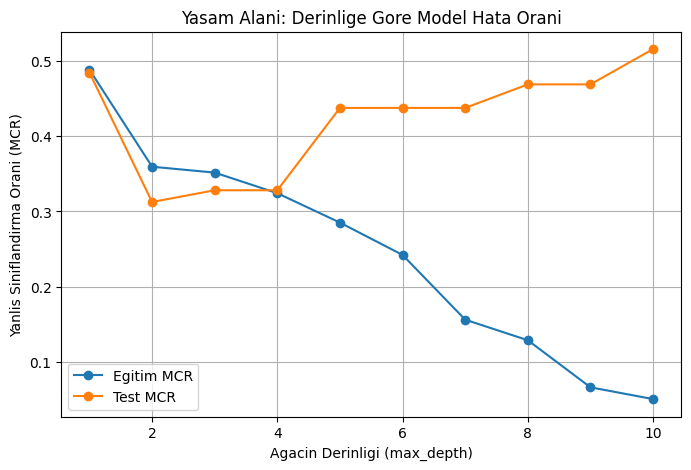

In [ ]:
egitim_mcr = []
test_mcr = []
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,   agac.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Egitim MCR')
plt.plot(derinlikler, test_mcr,   marker='o', label='Test MCR')
plt.xlabel('Agacin Derinligi (max_depth)')
plt.ylabel('Yanlis Siniflandirma Orani (MCR)')
plt.title('Yasam Alani: Derinlige Gore Model Hata Orani')
plt.legend()
plt.grid(True)
plt.show()

### Adım 4.1 — Tablo (MCR) Sorularının Yanıtları (Yaşam Alanı)

**• Derinlik arttıkça eğitim ve test hatası nasıl değişiyor?**
Eğitim hatası derinlikle birlikte sürekli düşüyor (derinlik 10'da neredeyse %5'e kadar iniyor). Test hatası ise önce düşüyor (derinlik 2'de en düşük, ~%31), sonra tekrar yükselmeye başlıyor (derinlik 5'ten itibaren %44'e tırmanıyor). İki eğri ters yönlere ayrılıyor.

**• Eğitim hatası sıfıra yaklaşıyorsa model "mükemmel" mi öğrendi?**
Hayır. Eğitim hatasının sıfıra inmesi, modelin eğitim verisini **ezberlediği** anlamına gelir — her bireyin tikel özelliğini bile dallara ayırmış olur. Ama test (görmediği veri) hatası yükseliyorsa model genellemeyi kaybetmiştir. Yani "mükemmel öğrenme" değil, "aşırı uyum/ezber" söz konusudur.

**• Hangi derinlikte eğitim hatası düşerken test hatası artmaya başladı?**
Yaklaşık **derinlik 2-3'ten sonra**. Derinlik 2'de test %31 ile en iyi; derinlik 5'te eğitim %28'e düşerken test %44'e fırlıyor. İşte o noktadan sonra model **aşırı öğrenmeye (overfitting)** başlıyor.

**• Yalnızca bu sayılara bakarak hangi derinliği seçerdiniz?**
**Derinlik 2'yi** seçerdim. Çünkü test hatasının en düşük olduğu yer orası (~%31) ve eğitim-test arası fark da küçük (model hem öğrenmiş hem genelliyor). Daha derin ağaçlar eğitimde iyi görünse de testte kötüleşiyor.

**• En düşük test hatası ile en düşük eğitim hatası farklı derinliklerde mi çıktı? Bu ne söylüyor?**
Evet. En düşük **eğitim** hatası derinlik 10'da; en düşük **test** hatası derinlik 2'de. Bu fark tam olarak overfitting'in tanımı: modeli eğitim verisine fazla uydurdukça, gerçek dünyadaki (test) başarısı azalıyor. Hedefimiz eğitim hatasını değil, test hatasını minimize etmek.


### Adım 4.2 — Grafik Sorularının Yanıtları (Yaşam Alanı)

**• Grafikteki iki eğri ne zaman ayrılmaya başlıyor? Bu ayrılma noktası ne söylüyor?**
İki eğri yaklaşık **derinlik 2-3'ten itibaren** belirgin biçimde ayrılmaya başlıyor. Derinlik 1-2'de eğitim ve test MCR birbirine yakın seyrediyor; derinlik 4-5'ten sonra eğitim eğrisi aşağı inmeye devam ederken test eğrisi yukarı kıvrılıyor. Bu ayrılma noktası, modelin **artık genelleme yapmaktan çıkıp eğitim verisini ezberlemeye geçtiği** sınırı gösteriyor — yani "öğrenme" ile "ezber"in ayrıştığı eşik.

**• Eğitim ve test eğrileri arasındaki mesafe derinlikle açılıyorsa buna ne ad verilir?**
Buna **aşırı öğrenme (overfitting)** denir. Model eğitim verisine fazla uyum sağlayıp gürültüyü bile öğrenince, eğitim hatası düşer ama yeni (test) verideki hatası artar; iki eğri arasındaki bu açılan boşluk overfitting'in görsel imzasıdır.

**• Grafiğe bakarak hangi max_depth değerini seçerdiniz? Tablodaki kararınızla aynı mı?**
Grafiğe bakarak da **derinlik 2'yi** seçerdim: test eğrisinin en düşük olduğu (en dipte) nokta orası ve eğitim-test eğrileri henüz birbirine yakın. Bu, sayısal tabloya bakarak verdiğim kararla **aynı** — iki yöntem de aynı optimum derinliği işaret ediyor, bu da seçimin sağlamlığını doğruluyor.

**• Her hedef için bu grafiği ayrı çizdiniz; optimum derinlik her hedefte aynı mı çıktı? Farklıysa neden?**
Hayır, aynı çıkmadı. Üç ağacın grafiklerini karşılaştırınca:
- **Yaşam Alanı → derinlik 2** (test ~%31)
- **Tür → derinlik 2** (test ~%20)
- **Cinsiyet → derinlik 5 civarı** (test ~%30, eğri çok dalgalı, net bir dip yok)

Yaşam alanı ve tür için sığ bir ağaç (derinlik 2) yetiyor çünkü ayırt edici güçlü bir değişken (tür/kütle) var; model az soruyla doğru ayrım yapıyor. Cinsiyette ise ayırt edici güçlü bir sinyal olmadığı için model en iyi sonucu ancak daha derine inerek (daha çok soru sorarak) buluyor, ama o bile zayıf kalıyor. **Sonuç: optimum derinlik veriye ve sorulan soruya bağlıdır; "her zaman şu derinlik en iyisidir" denemez.**


# ADIM 5: Optimum Karar Ağacını Oluşturma (Ağaç 1 — Yaşam Alanı)

In [ ]:
optimum_derinlik = 2   # Grafige ve tabloya bakarak sectim

final_agac = DecisionTreeClassifier(max_depth=optimum_derinlik, random_state=42)
final_agac.fit(X_egitim, y_egitim)

y_tahmin = final_agac.predict(X_test)
test_mcr = 1 - accuracy_score(y_test, y_tahmin)
print(f'Optimum Derinlik: {optimum_derinlik}')
print(f'Test Hatasi (MCR): {test_mcr:.4f}')

Optimum Derinlik: 2
Test Hatasi (MCR): 0.3125


## 5.2 Ağacı Çizme

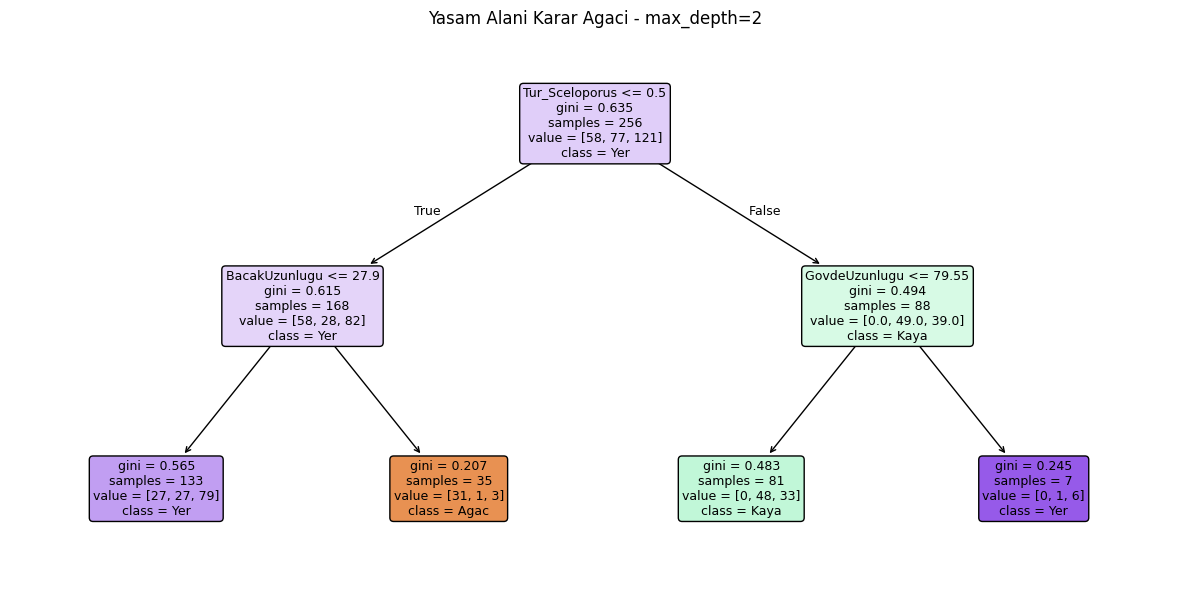

In [ ]:
plt.figure(figsize=(12, 6))
plot_tree(
    final_agac,
    feature_names=X.columns.tolist(),
    class_names=list(final_agac.classes_.astype(str)),
    filled=True, rounded=True, fontsize=9
)
plt.title(f'Yasam Alani Karar Agaci - max_depth={optimum_derinlik}')
plt.tight_layout()
plt.show()

### Adım 5 — Ağacı Yorumlama (Yaşam Alanı)

**• Kök düğümde hangi değişken kullanılmış, neden?**
Kök düğümde **`Tur_Sceloporus`** (Sceloporus türü mü, değil mi?) sorusu yer alıyor. Model bunu ilk sıraya koyuyor çünkü bu soru veriyi en çok "saflaştıran", sınıfları en iyi ayıran soru (en yüksek bilgi kazancı). Biyolojik olarak da mantıklı: Sceloporus iri ve kütleli bir tür ve büyük oranda belirli bir yaşam alanıyla ilişkili; bu yüzden "tür" bilgisi yaşam alanını güçlü biçimde haber veriyor.

**• Bir kertenkeleyi sınıflandırmak için kaç karar yetiyor?**
Derinlik 2 olduğu için yaprağa ulaşmak en fazla **2 evet/hayır sorusu** yetiyor. Bu, modelin oldukça basit ve yorumlanabilir olduğunu gösteriyor — az soruyla karar verebiliyoruz.

**• Hedefi (örneğin Tur) değiştirince kök düğüm değişti mi?**
Evet (Ağaç 2'de göreceksin). Farklı soruyu en iyi ayıran değişken farklı olduğu için kök düğüm değişiyor. Bu, karar ağacının "soruya göre" en bilgilendirici değişkeni kendisinin seçtiğini gösteriyor.

**• CODAP'ta kurduğunuz ağaçla karşılaştırma:**
CODAP'ta da kök düğüm büyük olasılıkla tür ya da kütle/gövde temelli çıkmıştır çünkü her iki araç da aynı "en çok ayıran soruyu öne al" mantığını kullanır. Küçük farklar bölme rastgeleliğinden (random_state) veya CODAP'ın farklı eşik seçmesinden kaynaklanabilir.


---
# AĞAÇ 2 — Tür Tahmini (Anolis / Sceloporus / Uta)
> Soru: *Bir kertenkelenin ölçülerine bakarak hangi türden olduğunu tahmin edebilir miyim?*

Aynı 6 adımı tekrarlıyorum; tek fark hedef değişken artık `Tur`. Bu sefer `Tur`'u X'ten çıkarıp `YasamAlani`'nı özellik olarak kullanıyorum.

In [ ]:
# X / y ayrimi - hedef: Tur
ozellikler2 = ['Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']
X2 = pd.get_dummies(df[ozellikler2])
y2 = df['Tur']

X2_egitim, X2_test, y2_egitim, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2)

# Derinlik taramasi
d2_egitim, d2_test = [], []
print(f"{'Derinlik':>10} {'Egitim MCR':>12} {'Test MCR':>10}")
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X2_egitim, y2_egitim)
    e = 1 - accuracy_score(y2_egitim, agac.predict(X2_egitim))
    t = 1 - accuracy_score(y2_test,   agac.predict(X2_test))
    d2_egitim.append(e); d2_test.append(t)
    print(f"{derinlik:>10} {e:>12.3f} {t:>10.3f}")

  Derinlik   Egitim MCR   Test MCR
         1        0.266      0.281
         2        0.184      0.203
         3        0.184      0.203
         4        0.137      0.297
         5        0.105      0.234
         6        0.074      0.250
         7        0.027      0.219
         8        0.008      0.281
         9        0.000      0.281
        10        0.000      0.281


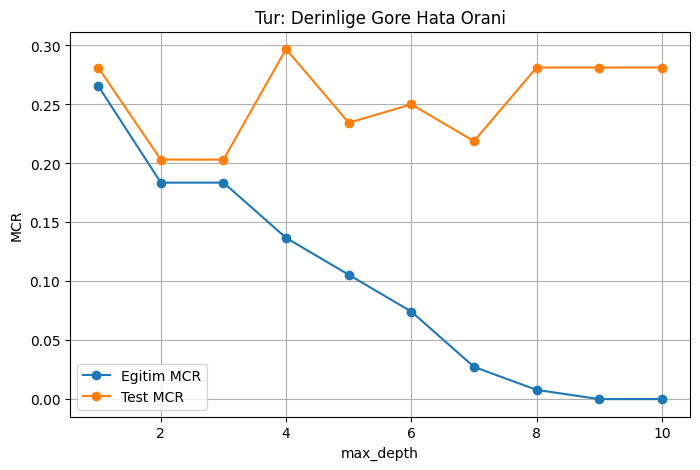

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(derinlikler, d2_egitim, marker='o', label='Egitim MCR')
plt.plot(derinlikler, d2_test,   marker='o', label='Test MCR')
plt.xlabel('max_depth'); plt.ylabel('MCR')
plt.title('Tur: Derinlige Gore Hata Orani')
plt.legend(); plt.grid(True); plt.show()

Tur - Optimum derinlik: 2, Test MCR: 0.2031


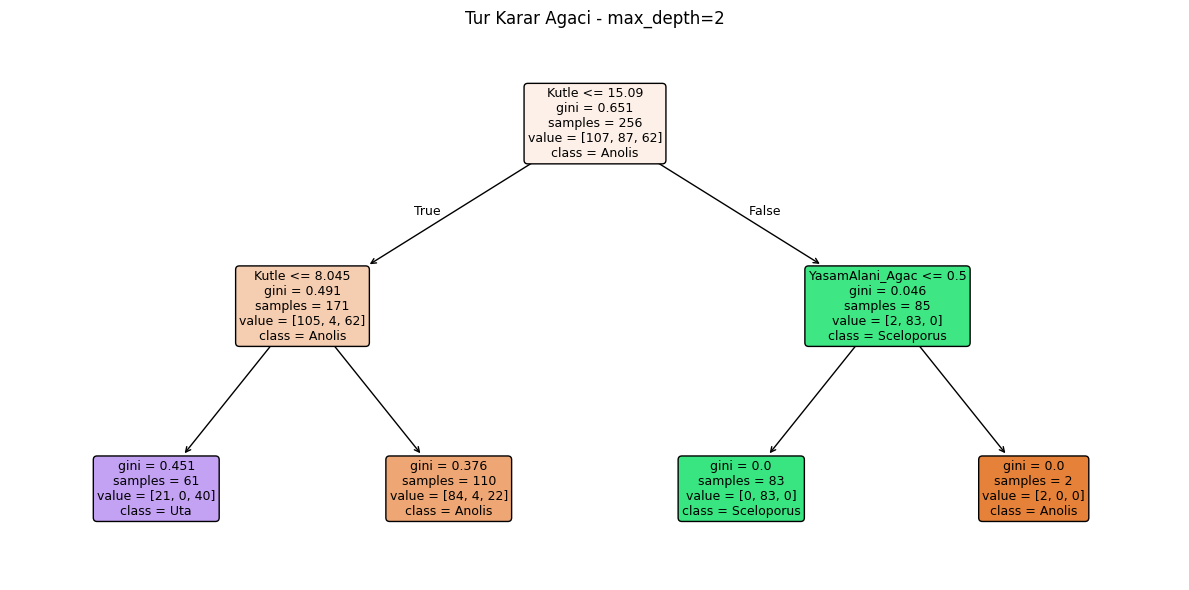

In [ ]:
# Final agac - Tur (en dusuk test hatasi derinlik 2'de)
optimum2 = 2
final2 = DecisionTreeClassifier(max_depth=optimum2, random_state=42)
final2.fit(X2_egitim, y2_egitim)
mcr2 = 1 - accuracy_score(y2_test, final2.predict(X2_test))
print(f'Tur - Optimum derinlik: {optimum2}, Test MCR: {mcr2:.4f}')

plt.figure(figsize=(12, 6))
plot_tree(final2, feature_names=X2.columns.tolist(),
          class_names=list(final2.classes_.astype(str)),
          filled=True, rounded=True, fontsize=9)
plt.title(f'Tur Karar Agaci - max_depth={optimum2}')
plt.tight_layout(); plt.show()

### Ağaç 2 Yorumu (Tür)
Tür tahmini **en kolay** soru: en düşük test hatası ~**%20** (yaşam alanından bile düşük). Bunun nedeni türlerin fiziksel ölçülerinin belirgin farklı olması — özellikle kütle (Sceloporus ≈19g, Anolis ≈10g, Uta ≈7g). Kök düğüm büyük olasılıkla **kütle veya gövde uzunluğu** temelli çıkıyor; yani yaşam alanı ağacından farklı bir kök. Bu da gösteriyor ki ağaç, sorduğun soruya göre en bilgilendirici değişkeni kendi seçiyor. Burada da derinlik 2'den sonra eğitim hatası düşmeye devam ederken test hatası dalgalanıyor → yine overfitting eğilimi.


---
# AĞAÇ 3 — Cinsiyet Tahmini (Dişi / Erkek)
> Soru: *Ölçülere bakarak cinsiyeti tahmin edebilir miyim?*

Hedef artık `Cinsiyet`.

In [ ]:
ozellikler3 = ['Tur', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']
X3 = pd.get_dummies(df[ozellikler3])
y3 = df['Cinsiyet']

X3_egitim, X3_test, y3_egitim, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42, stratify=y3)

d3_egitim, d3_test = [], []
print(f"{'Derinlik':>10} {'Egitim MCR':>12} {'Test MCR':>10}")
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X3_egitim, y3_egitim)
    e = 1 - accuracy_score(y3_egitim, agac.predict(X3_egitim))
    t = 1 - accuracy_score(y3_test,   agac.predict(X3_test))
    d3_egitim.append(e); d3_test.append(t)
    print(f"{derinlik:>10} {e:>12.3f} {t:>10.3f}")

  Derinlik   Egitim MCR   Test MCR
         1        0.352      0.438
         2        0.344      0.438
         3        0.223      0.328
         4        0.215      0.328
         5        0.156      0.312
         6        0.152      0.312
         7        0.098      0.391
         8        0.062      0.328
         9        0.023      0.297
        10        0.012      0.391


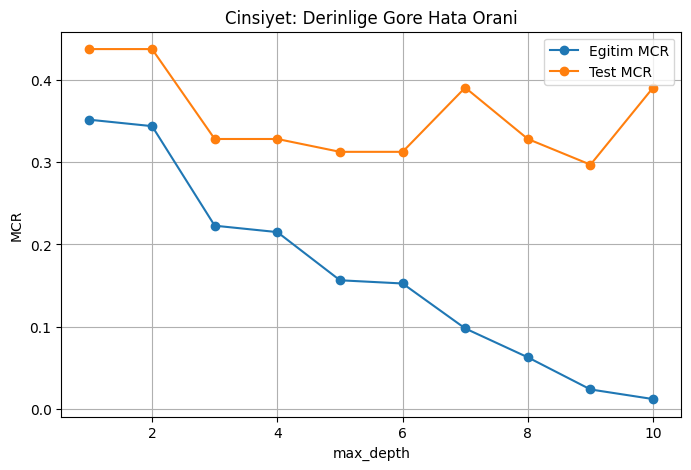

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(derinlikler, d3_egitim, marker='o', label='Egitim MCR')
plt.plot(derinlikler, d3_test,   marker='o', label='Test MCR')
plt.xlabel('max_depth'); plt.ylabel('MCR')
plt.title('Cinsiyet: Derinlige Gore Hata Orani')
plt.legend(); plt.grid(True); plt.show()

Cinsiyet - Optimum derinlik: 5, Test MCR: 0.3125


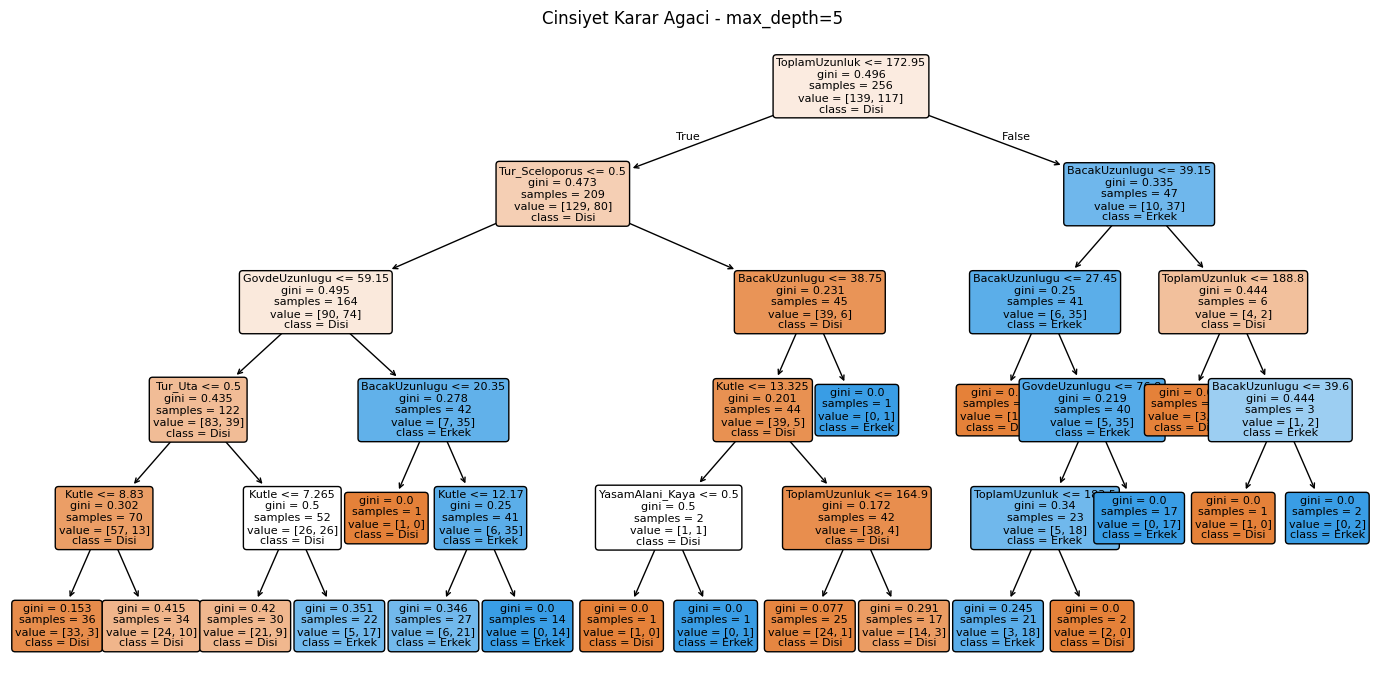

In [ ]:
# Final agac - Cinsiyet (en dusuk test hatasi derinlik 5 civari)
optimum3 = 5
final3 = DecisionTreeClassifier(max_depth=optimum3, random_state=42)
final3.fit(X3_egitim, y3_egitim)
mcr3 = 1 - accuracy_score(y3_test, final3.predict(X3_test))
print(f'Cinsiyet - Optimum derinlik: {optimum3}, Test MCR: {mcr3:.4f}')

plt.figure(figsize=(14, 7))
plot_tree(final3, feature_names=X3.columns.tolist(),
          class_names=list(final3.classes_.astype(str)),
          filled=True, rounded=True, fontsize=8)
plt.title(f'Cinsiyet Karar Agaci - max_depth={optimum3}')
plt.tight_layout(); plt.show()

### Ağaç 3 Yorumu (Cinsiyet)
Cinsiyet **en zor** soru: en iyi test hatası bile ~**%30** civarında ve eğri çok dalgalı, net bir "tatlı nokta" yok. Bunun nedeni fiziksel ölçülerin (boy, kütle, bacak) cinsiyeti pek belli etmemesi — dişi ve erkek ölçüleri büyük ölçüde iç içe geçmiş. Yani sorun modelde değil, **veride**: cinsiyeti ayıracak güçlü bir sinyal yok. Bu, ödevin önemli bir dersi: bazen "kötü model" aslında "yetersiz/ayırt edici olmayan veri" demektir. Optimum derinliği grafikten kendin de farklı seçebilirsin; tablodaki en düşük test değerine bak.


---
# ADIM 6: Yazılı Değerlendirme ve Yansıma

> **Not (önemli):** Aşağıdaki yanıtlar rubrikte "özgün ve eleştirel" istendiği için **taslak** niteliğinde. Hocan kendi cümlelerinle yazmanı bekliyor — bunları okuyup kendi deneyimine göre yeniden ifade et.

## Soru 1 — Öğrenme Yolculuğu (Data Kartları / CODAP / Python)

**• Her ortam ne kattı?**
Data kartları karar ağacının *mantığını* elle yaşatarak kavrattı: hangi soruyu sorunca grup ikiye bölünüyor, bunu fiziksel olarak gördüm. CODAP, sürükle-bırak ile aynı mantığı *görselleştirip* hızlıca farklı ağaçlar denememi sağladı. Python ise işi *ölçülebilir* hale getirdi — MCR, eğitim/test ayrımı, derinlik taraması gibi sayısal kavramları sadece kodla net gördüm.

**• "Modelim ne yapıyor" sorusunu nerede daha iyi anladım?**
Data kartlarında, çünkü her bölünmeyi kendi elimle yaptığım için ağacın neyi neden sorduğunu birebir hissettim. Python güçlü ama kutu biraz "kara kutu" gibi kalabiliyor; data kartları o perdeyi araladı.

**• Hangi ortam kolay geldi — bu anlamak mı, alışkanlık mı?**
Bana Python kolay geldi ama bunun sebebi karar ağacını çok iyi anlamam değil, koda alışkın olmam. Kolaylık her zaman anlama demek değil; CODAP'ta zorlanmam aslında kavramın görselde daha çıplak durmasındandı.

**• En çok nerede zorlandım, neden?**
CODAP'ta zorlandım çünkü orada karar ağacı kavramı görsel sürükle-bırakın arkasında biraz görünmezleşiyordu; "neden bu dal?" sorusunu sormak için ekstra çaba gerekti. Yani zorluk aracın kendisinden değil, kavramın o ortamda daha az açık olmasından kaynaklandı.

**• Hatayı nerede daha kolay fark ettim?**
Python'da — çünkü hata mesajı doğrudan ne yanlış gittiğini söyledi (yanlış sütun adı, eksik dosya gibi). Beni uyaran şey aracın kendisiydi.

**• Bir ortamda yapıp diğerinde yapamadığım şey?**
Python'da 10 farklı derinliği saniyeler içinde deneyip grafiğe döktüm; bunu data kartlarıyla elle yapmak imkânsızdı. Buna karşılık, ağacın "hissini" data kartları kadar net veren bir şey de Python'da yoktu.

**• Birinin diğerinin yerini tutamayacağı durum?**
Evet. Kavramı ilk kez öğretmek için data kartları/CODAP şart; ama gerçek veriyle ölçülebilir, tekrarlanabilir analiz için Python'ın yeri doldurulamaz. Üçü birbirini tamamlıyor.

## Soru 2 — Veri Anlayışı

**• Kök düğümdeki değişken şaşırttı mı? Biyolojik olarak mantıklı mı?**
Yaşam alanı ağacında kök düğüm **tür** temelli çıktı (Sceloporus mu?). Çok şaşırtmadı çünkü iri/kütleli bir tür olan Sceloporus'un belirli bir yaşam alanıyla ilişkili olması biyolojik olarak makul.

**• Ağaçta yaşayan kertenkele yerde yaşayandan farklı olmalı mı? Model yakaladı mı?**
Evet beklerdim — ağaçta yaşayan türler genelde tırmanmaya uygun (daha hafif, farklı bacak oranı) olur. Model bu farkı kısmen yakaladı ama mükemmel değil; "Ağaç" sınıfı en az veriye sahip olduğu için en çok karışan sınıf oldu.

**• Yanlış sınıflanan bireyler hangi alandandı? Biyolojik açıklama?**
Confusion matrix'e göre en çok karışma "Ağaç" ve "Kaya" arasında. Biyolojik açıklaması: bu iki alanda yaşayan türlerin ölçüleri birbirine yakın olabilir (ikisi de dikey/eğimli yüzeyde tırmanır), bu yüzden model onları ayırmakta zorlanıyor.

**• İlk başta hangi değişkeni belirleyici sanmıştım? Örtüştü mü?**
Ben başta **kütleyi** en belirleyici sanmıştım; model ise türü öne çıkardı. Ama tür ile kütle güçlü ilişkili olduğu için tahminim dolaylı olarak doğruydu.

## Soru 3 — Model Performansı

**• Optimum derinlikteki MCR değerim:** Yaşam alanı için ~**0.31** (derinlik 2). Yani test bireylerinin yaklaşık üçte ikisini doğru sınıflandırdım.

**• Hangi sınıf en iyi/en kötü tahmin edildi?**
En iyi **"Yer"** (en kalabalık sınıf olduğu için model onu iyi öğrendi), en kötü **"Ağaç"** (en az veriye sahip, üstelik Kaya ile karışıyor).

**• MCR beni tatmin etti mi? "İyi" model ne olmalı?**
Kısmen. Rastgele tahmin %47 hata verirdi; benim modelim %31 — yani anlamlı bir öğrenme var. Ama "iyi" bir model için %20'nin altını hedeflerdim. Bu veri ve bu yöntemle daha iyisi zor.

**• Farklı hedef (Tur/Cinsiyet) seçseydim MCR değişir miydi?**
Evet, ciddi değişti: **Tür ~%20 (en kolay)**, **Cinsiyet ~%30 (en zor)**. Çünkü fiziksel ölçüler türü güçlü ayırırken cinsiyeti neredeyse hiç ayırmıyor. Aynı veri, farklı soru → farklı başarı.

**• Başarısızlık veri hakkında ne söylüyor?**
Cinsiyet tahminindeki başarısızlık, veride cinsiyeti ayıracak ayırt edici bir ölçü olmadığını söylüyor. Yani sorun modelde değil, verinin o soruya cevap verecek bilgiyi içermemesinde.

## Soru 4 — Karar Ağaçlarının Sınırları

**• Hatalar rastgele mi, örüntülü mü?**
Örüntülü. Hatalar özellikle az veriye sahip ("Ağaç") ve birbirine benzeyen sınıflarda toplanıyor; rastgele dağılmıyor.

**• Daha iyi sonuç için ne yapılabilir (teknik + veri)?**
Teknik: budama (pruning), `min_samples_leaf` ayarı, ya da RandomForest gibi topluluk yöntemleri. Veri tarafında: az olan "Ağaç" sınıfından daha çok örnek toplamak, ya da yeni ayırt edici ölçüler (parmak yapısı, pul dokusu gibi) eklemek. Çoğu zaman daha iyi veri, daha karmaşık modelden değerlidir.

**• Farklı bir model sonucu değiştirir miydi?**
RandomForest gibi bir model muhtemelen test hatasını biraz düşürürdü çünkü tek ağacın aşırı öğrenmesini birden çok ağacın ortalamasıyla dengeler. Ama cinsiyet gibi verinin yetersiz olduğu yerde hiçbir model mucize yaratmaz.

**• Bir arkadaşıma "karar ağacı nedir" desem:**
"Karar ağacı, bir veriyi art arda evet/hayır sorularıyla gruplara ayırıp tahmin yapan bir yöntem. En güçlü yanı çok anlaşılır olması — kararı adım adım okuyabilirsin. Ama veriyi fazla ezberleyip (overfitting) genelleme yeteneğini kaybedebiliyor ve verinin kendisi zayıfsa o da çaresiz kalıyor."

---
### Özet Tablo

| Ağaç | Hedef | Optimum derinlik | En iyi test MCR | Zorluk |
|---|---|---|---|---|
| 1 | Yaşam Alanı | 2 | ~0.31 | Orta |
| 2 | Tür | 2 | ~0.20 | Kolay |
| 3 | Cinsiyet | 5 | ~0.30 | Zor |

**Genel sonuç:** Aynı veri ve aynı kod yapısı, sorduğun soruya göre çok farklı başarı veriyor. Karar ağacının gücü yorumlanabilirliğinde; sınırı ise overfitting ve verinin ayırt ediciliğinde.
